# Verificador independente e heurísticas construtivas

Este notebook emprega exclusivamente as 14 instâncias de desenvolvimento (`set = dev` em `data/reference/split.csv`) para validar o verificador independente frente a planos intencionalmente defeituosos, avaliar duas heurísticas construtivas determinísticas diante da referência do SINTEF e compará-las às construções iniciais do OR-Tools (Perron & Furnon, 2026) sem busca local.

A função `verify` recalcula todas as métricas diretamente a partir das rotas em precisão dupla, conferindo capacidade dos veículos, visita única por cliente, janelas de atendimento com espera permitida antes da abertura (Toth & Vigo, 2014), retorno ao depósito dentro do horizonte e limite de frota, usando distância euclidiana exata sem arredondamento. Todas as medidas reportadas no projeto provêm desse verificador, independentemente do valor objetivo interno do solver.

As baselines consistem em duas abordagens construtivas simples: a heurística gulosa por prazo ordena os clientes pelo fechamento da janela (regra do prazo mais cedo; Jackson, 1955) e aloca cada visita na primeira rota em que permanece factível (*first-fit*; Johnson, 1974), abrindo nova rota quando necessário; já o vizinho mais próximo com janelas (Solomon, 1987) constrói rotas sequencialmente escolhendo o próximo cliente factível que minimiza `0,4·distância + 0,4·diferença_de_tempo + 0,2·urgência`. Como o SINTEF adota objetivo hierárquico de frota seguida por distância (Bräysy & Gendreau, 2005a; SINTEF, 2008), o Δ de veículos é sempre apresentado e o gap de distância só tem interpretação quando a frota iguala a referência, lembrando que os valores do SINTEF são as melhores soluções conhecidas.

## 1. Preparação do ambiente

Nesta etapa carregam-se as 14 instâncias de desenvolvimento, as referências SINTEF correspondentes e os resultados da grade de desenvolvimento congelada em `outputs/frozen/`, por meio de carregadores que recusam qualquer instância de avaliação. A tabela resume os dados carregados.

In [1]:
LANG = "pt"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import analysis, benchmark, diagnostics, eda, paths, results, viz_results
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
instances, sintef = results.load_dev_instances(P["sintef_zip"], P["sintef_bks"], split)
dev = results.dev_names(split)
grid = results.load_dev_grid(R["dev_grid"], split)

display(eda.localize_columns(analysis.dev_instance_table(instances, sintef), LANG))

,Instância,Família,Nº de clientes,Capacidade (Q),Horizonte,Veículos SINTEF,Distância SINTEF
0,C103,C1,100,200,1236.0,10,828.06
1,C106,C1,100,200,1236.0,10,828.94
2,C203,C2,100,700,3390.0,3,591.17
3,C206,C2,100,700,3390.0,3,588.49
4,R108,R1,100,200,230.0,9,960.88
5,R110,R1,100,200,230.0,10,1118.84
6,R111,R1,100,200,230.0,10,1096.73
7,R201,R2,100,1000,1000.0,4,1252.37
8,R202,R2,100,1000,1000.0,3,1191.70
9,R207,R2,100,1000,1000.0,2,890.61


### Insight

Foram carregadas as 14 instâncias de desenvolvimento com 100 clientes cada: duas de cada série C (C103, C106; C203, C206), três de cada série R (R108, R110, R111; R201, R202, R207) e duas de cada série RC (RC106, RC108; RC203, RC206). As capacidades variam entre 200 (séries 1), 700 (C2) e 1000 (R2 e RC2), com horizontes de 230 (R1) a 3390 (C2) e frotas SINTEF entre 2 veículos (R207) e 11 (RC106). Por se tratar de uma amostra estratificada de 14 instâncias entre 56, ela oferece apenas uma base controlada para testes iniciais. Antes de medir as baselines, confere-se a capacidade do verificador de detectar falhas explícitas.

## 2. O verificador diante de planos quebrados

Para atestar a detecção de violações, parte-se do plano factível gerado pelo vizinho mais próximo em R108 e constroem-se quatro variantes defeituosas: remoção de um cliente, duplicação de um cliente anexado à última rota, deslocamento do cliente de prazo mais cedo para o fim de outra rota e fusão das duas rotas mais carregadas. A tabela contabiliza as violações acusadas em cada variante.

In [2]:
r108 = instances["R108"]
nn_plan = analysis.baseline_routes(analysis.run_baselines(instances, sintef, ["R108"]), "R108", "nearest_neighbor_tw")
variants = diagnostics.demo_violations(r108, nn_plan)

display(eda.localize_columns(diagnostics.violation_table(r108, variants, LANG), LANG))

,Variante,Factível,Veículos,Clientes não atendidos,Clientes repetidos,Janelas violadas,Rotas acima da capacidade,Retornos tardios ao depósito
0,Plano original (vizinho mais próximo),True,12,0,0,0,0,0
1,Um cliente removido,False,12,1,0,0,0,0
2,Um cliente duplicado,False,12,0,1,1,0,1
3,Um cliente movido para fora da janela,False,12,0,0,1,0,0
4,Duas rotas fundidas,False,11,0,0,11,1,1


### Insight

O plano original do vizinho mais próximo em R108 passa sem violações com 12 veículos, enquanto cada variante perturbada é reprovada na categoria esperada: cliente removido acusa 1 cliente não atendido; cliente duplicado gera 1 visita repetida; cliente deslocado acusa 1 janela violada; e a fusão das rotas mais cheias acusa 1 rota acima da capacidade em 11 veículos. Violações secundárias também surgem quando há encadeamento temporal: a visita duplicada ao final da rota provocou ainda 1 janela violada e 1 retorno tardio ao depósito, e a rota fundida produziu 11 violações de janela e 1 retorno tardio por exceder o horizonte, ao passo que a perturbação isolada de janela afetou apenas o cliente movido. Essa demonstração ilustra a captura das categorias de erro em um caso concreto, complementando os testes unitários em instâncias sintéticas. Em seguida, as duas baselines são executadas sobre as 14 instâncias.

## 3. Baselines nas 14 instâncias de desenvolvimento

A tabela abaixo compara as duas heurísticas construtivas contra a referência SINTEF nas 14 instâncias, exibindo veículos de referência, frota obtida, distância total, tempo de execução ao vivo (medido via `perf_counter`) e Δ de veículos segundo o verificador.

In [3]:
baselines = analysis.run_baselines(instances, sintef, dev)

display(eda.localize_columns(analysis.baseline_table(baselines, LANG), LANG))

,Instância,Família,Veículos SINTEF,Gulosa por prazo · Veículos,Gulosa por prazo · Distância total,Gulosa por prazo · Tempo de execução (s),Gulosa por prazo · Δ veículos,Vizinho mais próximo com janelas · Veículos,Vizinho mais próximo com janelas · Distância total,Vizinho mais próximo com janelas · Tempo de execução (s),Vizinho mais próximo com janelas · Δ veículos
0,C103,C1,10,12,3472.1,0.0021,2,11,2078.9,0.0246,1
1,C106,C1,10,13,2876.0,0.0022,3,11,1630.9,0.0243,1
2,C203,C2,3,5,3127.5,0.0016,2,4,1765.7,0.0282,1
3,C206,C2,3,4,3070.7,0.0015,1,3,919.6,0.0275,0
4,R108,R1,9,21,3059.1,0.0034,12,12,1324.2,0.0256,3
5,R110,R1,10,19,2668.2,0.0028,9,13,1596.7,0.0247,3
6,R111,R1,10,19,2306.5,0.0026,9,12,1520.8,0.0248,2
7,R201,R2,4,6,2719.2,0.0015,2,5,2150.4,0.0260,1
8,R202,R2,3,5,2598.3,0.0015,2,4,1870.8,0.0267,1
9,R207,R2,2,6,3110.8,0.0016,4,3,1604.3,0.0277,1


### Insight

Ambas as baselines utilizam mais veículos do que a referência em quase todo o conjunto. A gulosa por prazo consome de 1 a 12 veículos extras (como 21 contra 9 em R108 e 4 contra 3 em C206), enquanto o vizinho mais próximo varia de 0 a +3 veículos (14 contra 11 em RC106; +3 em R108 e R110). A única igualdade de frota ocorre em C206 pelo vizinho mais próximo (3 veículos), porém com distância de 919,6 contra 588,49 do SINTEF. As distâncias totais variam de 920 a 3544 (muito acima da faixa de 589 a 1425 da referência), sendo diretamente comparável apenas a de C206 devido à diferença de frota nas demais. Os tempos de execução ficam abaixo de 0,01 s para a gulosa e 0,07 s para o vizinho mais próximo, sem variabilidade por serem métodos determinísticos frente a referências que são melhores soluções conhecidas. A tabela seguinte agrega os resultados por família e checa a reprodutibilidade contra a grade congelada.

Para conferir o comportamento por família e assegurar consistência com os arquivos congelados, as tabelas seguintes apresentam o Δ médio de veículos, a contagem de soluções factíveis e a verificação de igualdade exata (veículos e distância) frente às linhas das baselines gravadas na grade de desenvolvimento.

In [4]:
display(eda.localize_columns(analysis.baseline_family_summary(baselines, LANG), LANG))
display(eda.localize_columns(analysis.baseline_checks(baselines, grid, LANG), LANG))

,Família,Nº de instâncias,Gulosa por prazo · Δ veículos médio,Gulosa por prazo · Factíveis,Vizinho mais próximo com janelas · Δ veículos médio,Vizinho mais próximo com janelas · Factíveis
0,C1,2,2.50,2,1.00,2
1,C2,2,1.50,2,0.50,2
2,R1,3,10.00,3,2.67,3
3,R2,3,2.67,3,1.00,3
4,RC1,2,8.00,2,2.50,2
5,RC2,2,3.50,2,1.00,2
6,Total,14,4.93,14,1.50,14


,Indicador,Valor
0,Soluções factíveis no verificador,28 / 28
1,Soluções idênticas às da grade congelada (veíc...,28 / 28


### Insight

No agregado das 14 instâncias, a gulosa registra Δ médio de 4,93 veículos, oscilando entre 1,50 em C2 e 10,00 em R1 ou 8,00 em RC1, ao passo que o vizinho mais próximo alcança Δ médio de 1,50, variando de 0,50 (C2) a 2,67 (R1) e 2,50 (RC1). Em ambos os métodos, as séries 1 de R e RC (janelas estreitas e horizonte curto) ficam mais distantes da referência, enquanto C2 fica mais próxima, embora as causas dessa associação com apenas duas ou três instâncias por família não sejam testadas aqui. As duas conferências fecham com 28 de 28 planos factíveis e idênticos em frota e distância à grade congelada utilizada no notebook 04. Na seção 4, essas duas baselines são posicionadas diante das estratégias iniciais do OR-Tools sem busca local.

## 4. Comparação com as construções do OR-Tools sem busca local

A grade congelada inclui as três estratégias de solução inicial do OR-Tools executadas sem metaheurística (`NONE`) nas mesmas 14 instâncias. A tabela e os gráficos contrapõem as cinco heurísticas construtivas pelo Δ médio de veículos e pelo excesso mediano de distância sobre o SINTEF (mantido de forma puramente descritiva quando a frota diverge da referência, conforme indicado pela coluna de igualdade de frota).

,Método,Nº de instâncias,Factíveis,Δ veículos médio,Excesso mediano de distância (%),Instâncias com frota igual à referência,"Gap mediano, frota igual (%)"
0,Gulosa por prazo,14,14,4.93,213.8,0,-
1,Vizinho mais próximo com janelas,14,14,1.50,64.3,1,56.3
2,OR-Tools: inserção paralela mais barata (sem b...,14,14,1.86,51.3,1,6.8
3,OR-Tools: arco mais barato do caminho (sem bus...,14,14,8.36,57.6,0,-
4,OR-Tools: Savings (sem busca local),14,14,2.79,29.8,0,-


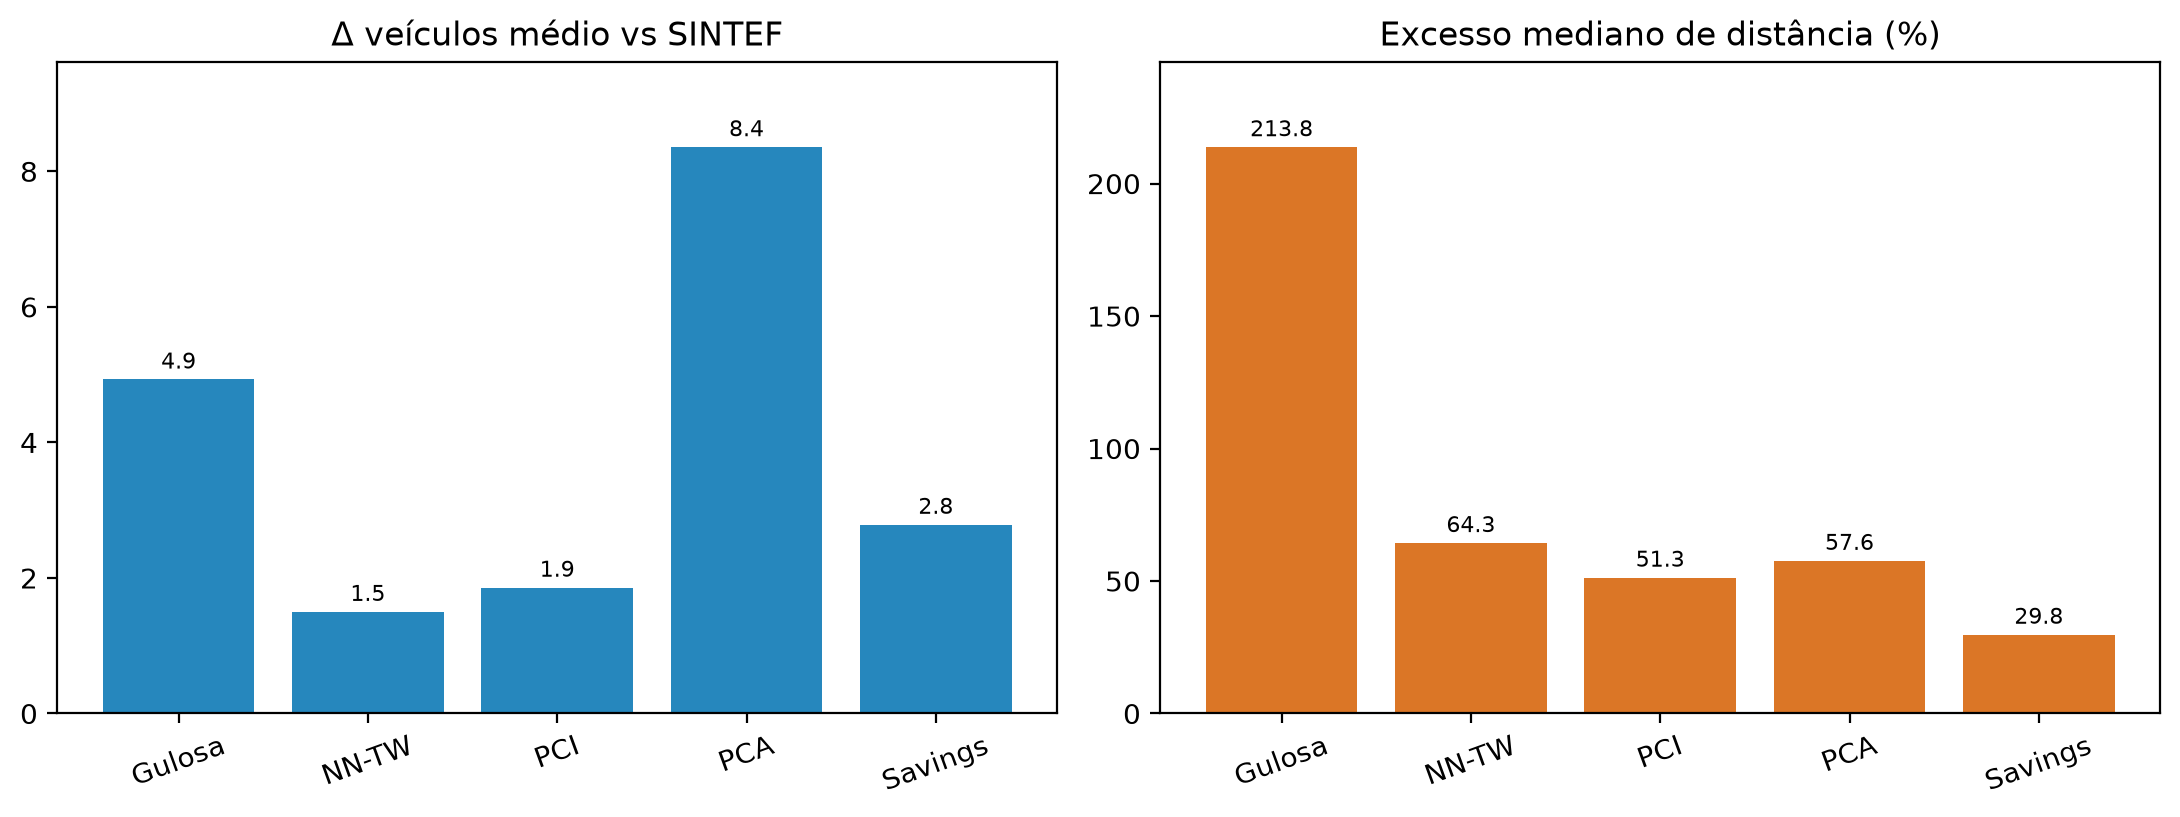

In [5]:
comparison = analysis.construction_comparison(grid, LANG)

display(eda.localize_columns(analysis.construction_table(comparison), LANG))

viz_results.plot_construction_comparison(comparison, LANG)
plt.show()

### Insight

Sem busca local, todas as cinco construções produzem soluções factíveis nas 14 instâncias, mas invertem posições segundo o critério observado. Pelo Δ médio de veículos, o vizinho mais próximo (1,50) e a inserção paralela mais barata (1,86) superam o Savings (2,79), a gulosa (4,93) e o arco mais barato do caminho (8,36). Pelo excesso mediano de distância sobre o SINTEF, o Savings lidera com 29,8%, seguido pela inserção paralela (51,3%), arco mais barato (57,6%), vizinho mais próximo (64,3%) e gulosa (213,8%). Apenas o vizinho mais próximo e a inserção paralela igualam a frota de referência em uma instância cada (com excessos de distância de 56,3% e 6,8%, respectivamente); nos demais casos, os excessos comparam frotas distintas e têm valor apenas descritivo. Pelo critério principal de tamanho de frota em rodada única sobre 14 instâncias, o vizinho mais próximo não fica atrás das construções puras do OR-Tools. A seguir, analisam-se os traçados espaciais gerados em uma instância agrupada.

## 5. Mapas de rotas em C103

Para ilustrar as diferenças geométricas entre os métodos construtivos, o gráfico exibe as rotas obtidas para C103 pela gulosa por prazo, pelo vizinho mais próximo e pela heurística Savings do OR-Tools (Clarke & Wright, 1964) sem busca local, extraída do JSON congelado. As cores diferenciam rotas individuais, o quadrado vermelho indica o depósito e os títulos reportam frota e distância recalculadas pelo verificador.

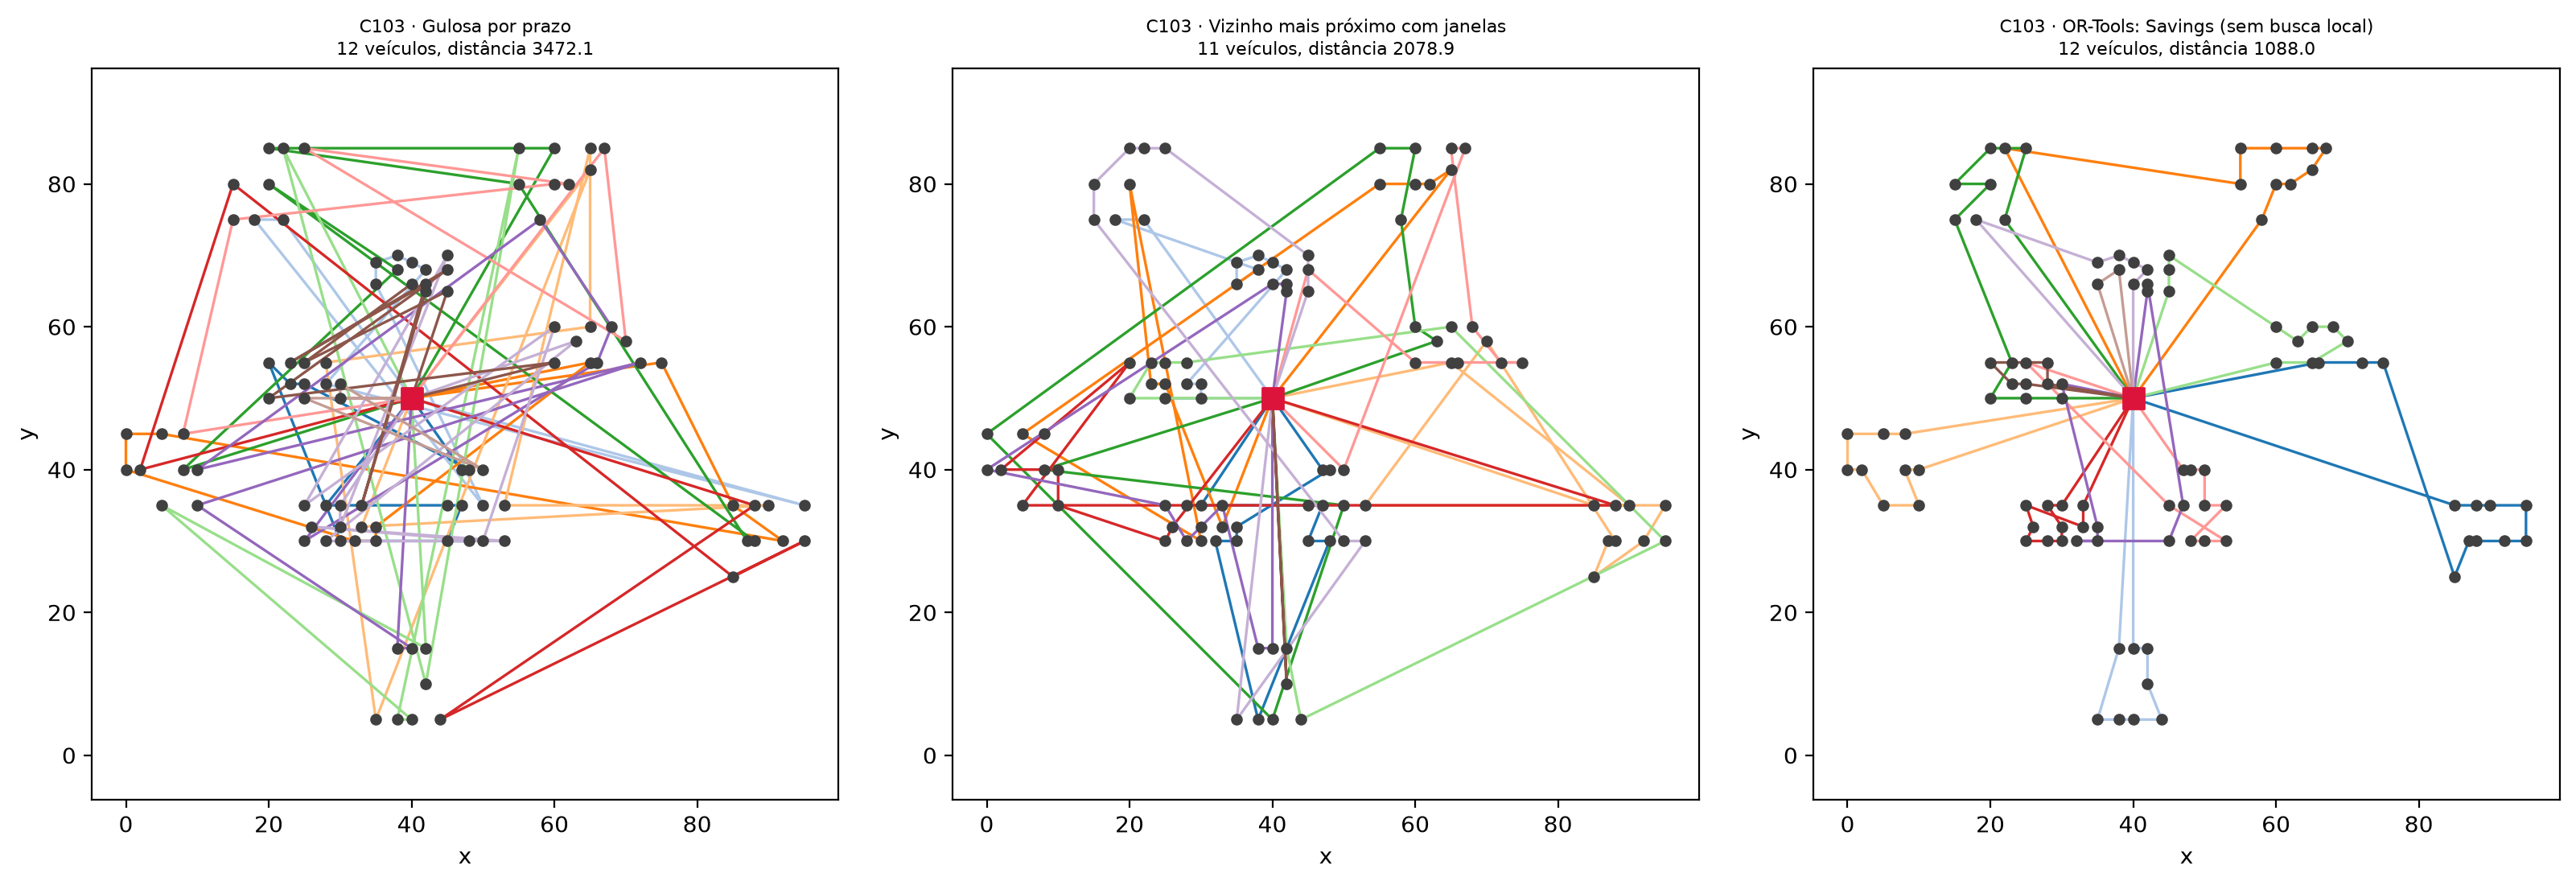

In [6]:
viz_results.plot_route_panels(analysis.baseline_panels("C103", instances, baselines, grid, LANG), LANG)
plt.show()

### Insight

Em C103, as três construções utilizam entre 11 e 12 veículos contra 10 da referência: a gulosa usa 12 veículos (distância 3472,1), o vizinho mais próximo usa 11 (2078,9) e o Savings do OR-Tools usa 12 (1088,0). Nos mapas, gulosa e vizinho mais próximo traçam segmentos longos que cruzam o plano ligando agrupamentos distantes, enquanto o Savings concentra as rotas em núcleos compactos ou vizinhos imediatos, explicando a distância muito inferior sem reduzir a frota em relação ao vizinho mais próximo (12 contra 11). Trata-se de uma leitura qualitativa de uma única instância, cujas cores servem apenas para distinguir percursos. O efeito da aplicação de busca local sobre essas construções é examinado no notebook 04.

## 6. Síntese e próximo passo

O verificador independente identificou corretamente as quatro categorias de falha injetadas (cliente ausente, visita duplicada, violação de janela e excesso de capacidade) e fornece todas as métricas utilizadas nas comparações. Nas 14 instâncias de desenvolvimento, as duas baselines próprias são integralmente factíveis e reproduzem a grade congelada, obtendo Δ médio de 4,93 veículos na gulosa por prazo e 1,50 no vizinho mais próximo com janelas, com maior afastamento da referência nas séries 1 de R e RC. Sem busca local, as construções do OR-Tools alcançam Δ médio de 1,86 (inserção paralela), 2,79 (Savings) e 8,36 (arco mais barato), igualando a frota SINTEF em no máximo uma instância. Como o excesso mediano de distância só é comparável sob frota idêntica à referência, o Δ de veículos permanece como critério principal.

Na etapa seguinte (notebook 04), o torneio pré-registrado de desenvolvimento aplica metaheurísticas de busca local sobre essas construções para definir a configuração congelada, sempre frente às melhores soluções conhecidas do SINTEF.

## Referências

- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- Clarke, G., & Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research, 12*(4), 568–581.
- Jackson, J. R. (1955). *Scheduling a production line to minimize maximum tardiness* (Research Report 43). Management Science Research Project, University of California, Los Angeles.
- Johnson, D. S. (1974). Fast algorithms for bin packing. *Journal of Computer and System Sciences, 8*(3), 272–314.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.